In [1]:
#MEMUAT DATASET KANKER PAYUDARA

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

# Memuat dataset
cancer = load_breast_cancer(as_frame=True)
df_b = cancer.frame

print("Bentuk Data:", df_b.shape)
df_b.head()

Bentuk Data: (569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


/tmp/ipykernel_775/3599313367.py:7: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(['Ganas (0)', 'Jinak (1)'])
/tmp/ipykernel_775/3599313367.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(['Ganas (0)', 'Jinak (1)'])


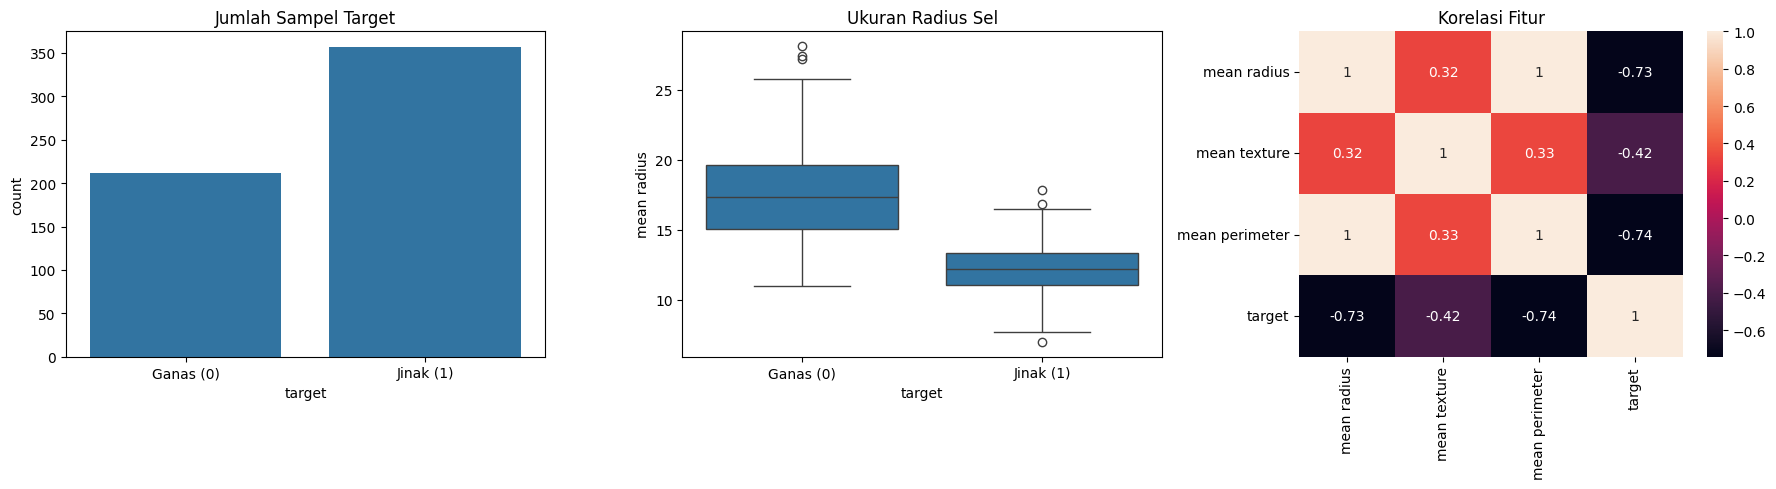

In [2]:
# EKSPLORASI DAN VISUALISASI DATA

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Grafik 1: Perbandingan Jumlah Kelas Ganas vs Jinak
sns.countplot(x='target', data=df_b, ax=axes[0])
axes[0].set_xticklabels(['Ganas (0)', 'Jinak (1)'])
axes[0].set_title('Jumlah Sampel Target')

# Grafik 2: Ukuran Radius Sel berdasarkan Kategori
sns.boxplot(x='target', y='mean radius', data=df_b, ax=axes[1])
axes[1].set_xticklabels(['Ganas (0)', 'Jinak (1)'])
axes[1].set_title('Ukuran Radius Sel')

# Grafik 3: Heatmap Korelasi
sns.heatmap(df_b[['mean radius', 'mean texture', 'mean perimeter', 'target']].corr(), annot=True, ax=axes[2])
axes[2].set_title('Korelasi Fitur')

plt.tight_layout()
plt.show()

In [4]:
# PEMBAGIAN DATA DENGAN STRATIFY DAN SCALING

X_b = df_b.drop(columns=['target'])
y_b = df_b['target']

# Pembagian Data (Stratify memastikan proporsi kelas seimbang di data latih & uji)
X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(
    X_b, y_b, test_size=0.2, random_state=42, stratify=y_b
)

# Scaling
scaler_b = StandardScaler()
X_train_b_scaled = scaler_b.fit_transform(X_train_b)
X_test_b_scaled = scaler_b.transform(X_test_b)

Akurasi  : 0.9825
Presisi  : 0.9861
Recall   : 0.9861
F1-Score : 0.9861


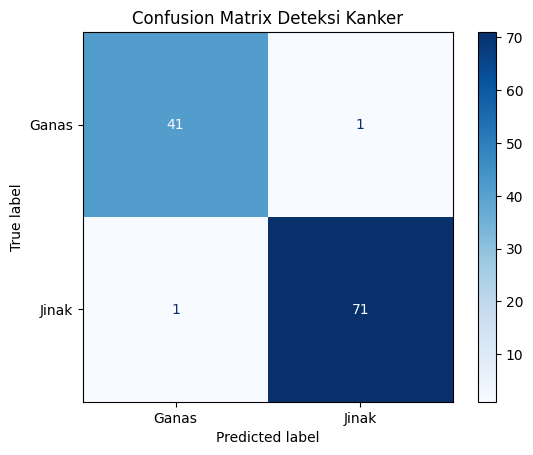

In [5]:
# PELATIHAN MODEL DAN EVALUASI KLASIFIKASI

# Melatih Logistic Regression
model_b = LogisticRegression()
model_b.fit(X_train_b_scaled, y_train_b)

# Prediksi
y_pred_b = model_b.predict(X_test_b_scaled)

# Menghitung Metrik Klasifikasi
print(f"Akurasi  : {accuracy_score(y_test_b, y_pred_b):.4f}")
print(f"Presisi  : {precision_score(y_test_b, y_pred_b):.4f}")
print(f"Recall   : {recall_score(y_test_b, y_pred_b):.4f}")
print(f"F1-Score : {f1_score(y_test_b, y_pred_b):.4f}")

# Tampilkan Confusion Matrix (Matriks Kebingungan)
cm = confusion_matrix(y_test_b, y_pred_b)
ConfusionMatrixDisplay(cm, display_labels=['Ganas', 'Jinak']).plot(cmap='Blues')
plt.title('Confusion Matrix Deteksi Kanker')
plt.show()